# # 12 · Vision Transformer & a LLaVA-style vision-language model
#
# **ViT**: cut the image into patches, linearly embed each patch, add position embeddings and a `[CLS]` token, and run a
# plain Transformer *encoder*. **VLM**: use that vision encoder as the "eyes" of a language model — a small **projector**
# maps image-patch features into the LM's token-embedding space, and the LM then continues the sequence in text
# (the LLaVA / PaliGemma / Idefics recipe).

---

### At a glance

| | |
|---|---|
| **Family** | Vision & multimodal |
| **Representative models** | ViT, CLIP, LLaVA, PaliGemma, Idefics |
| **Core idea** | Turn image patches into tokens; project them into an LLM's embedding space. |
| **Compute / memory** | O(P²) in the number of patches; image tokens add to the LM context |
| **Dataset** | sklearn 8×8 digits |
| **Runtime** | ≈ 31 s on a laptop CPU |

### What you will learn

- Build a ViT and visualise [CLS] attention
- Assemble a LLaVA-style vision-language model (encoder → projector → LM)

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device()
dg = load_digits_data(); Xtr, ytr, Xva, yva = [dg[k].to(device) for k in ("x_train", "y_train", "x_val", "y_val")]; P = 2   # 8x8 image, 2x2 patches -> 16 patches

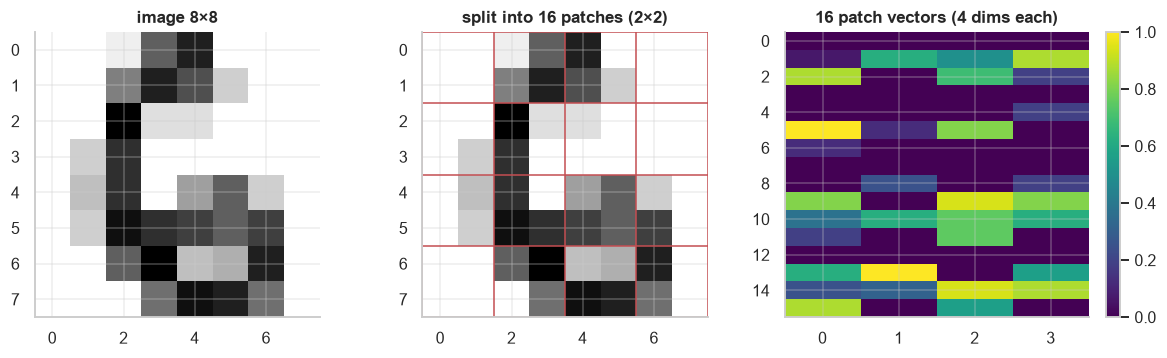

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4)); img = Xtr[0].cpu()
axs[0].imshow(img, cmap="gray_r"); axs[0].set_title("image 8×8")
axs[1].imshow(img, cmap="gray_r")
for k in range(0, 9, P): axs[1].axhline(k - .5, color="r", lw=1); axs[1].axvline(k - .5, color="r", lw=1)
axs[1].set_title("split into 16 patches (2×2)")
pt = img.unfold(0, P, P).unfold(1, P, P).reshape(16, -1); plot_heatmap(pt, title="16 patch vectors (4 dims each)", ax=axs[2]); plt.tight_layout(); plt.show()

# ## ViT

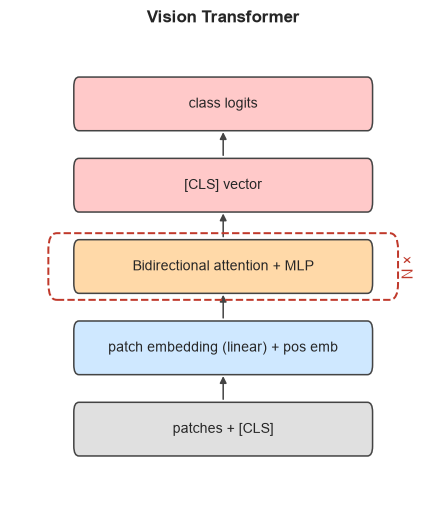

152,202 params
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ViT                                      [1, 8, 8]                 [1, 10]                   1,152
├─Linear: 1-1                            [1, 16, 4]                [1, 16, 64]               320
├─ModuleList: 1-2                        --                        --                        149,952
├─LayerNorm: 1-3                         [1, 17, 64]               [1, 17, 64]               128
├─Linear: 1-4                            [1, 64]                   [1, 10]                   650
Total params: 152,202
Trainable params: 152,202
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.15
Input size (MB): 0.39
Forward/backward pass size (MB): 0.30
Params size (MB): 0.60
Estimated Total Size (MB): 1.30


ViT validation accuracy: 70.4%


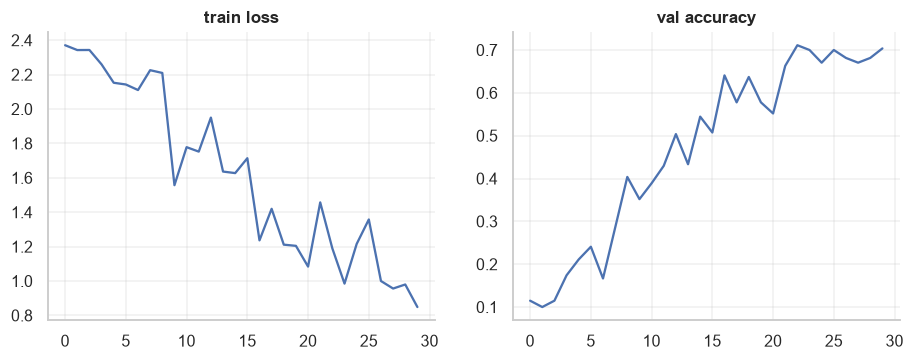

In [3]:
block_diagram([("class logits", "out"), ("[CLS] vector", "out"), ("Bidirectional attention + MLP", "attn*"), ("patch embedding (linear) + pos emb", "embed"), ("patches + [CLS]", "other")][::-1], title="Vision Transformer", repeat="N ×")
class ViT(nn.Module):
    def __init__(s, d=64, n=3, h=4, ncls=10):
        super().__init__(); s.patch = nn.Linear(P * P, d); s.cls = nn.Parameter(torch.zeros(1, 1, d)); s.pos = nn.Parameter(torch.randn(1, 17, d) * .02)
        s.blocks = nn.ModuleList([Block(d, Attention(d, h, causal=False), GELUMLP(d), norm=nn.LayerNorm) for _ in range(n)]); s.norm = nn.LayerNorm(d); s.head = nn.Linear(d, ncls)
    def features(s, img):                                      # (B,8,8) -> (B,17,d)
        B = img.size(0); p = img.unfold(1, P, P).unfold(2, P, P).reshape(B, 16, -1)
        x = torch.cat([s.cls.expand(B, -1, -1), s.patch(p)], 1) + s.pos
        for b in s.blocks: x, _ = b(x)
        return s.norm(x)
    def forward(s, img): return s.head(s.features(img)[:, 0])
vit = ViT().to(device); print(f"{count_params(vit):,} params")
_ = show_summary(vit, input_data=Xtr[:1], depth=1)
opt = torch.optim.AdamW(vit.parameters(), lr=2e-3, weight_decay=.05); tl, va = [], []
for ep in range(30):
    perm = torch.randperm(len(Xtr), device=device); vit.train()
    for i in range(0, len(Xtr), 64):
        ix = perm[i:i+64]; x = Xtr[ix]; shift = torch.randint(-1, 2, (2,)).tolist(); x = torch.roll(x, shift, (1, 2))   # tiny augmentation
        loss = F.cross_entropy(vit(x), ytr[ix]); opt.zero_grad(); loss.backward(); opt.step()
    vit.eval(); 
    with torch.no_grad(): va.append((vit(Xva).argmax(-1) == yva).float().mean().item())
    tl.append(loss.item())
print(f"ViT validation accuracy: {va[-1]:.1%}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); ax[0].plot(tl); ax[0].set_title("train loss"); ax[1].plot(va); ax[1].set_title("val accuracy"); [a.grid(alpha=.3) for a in ax]; plt.show()

# ## Where does [CLS] look?
# Attention of the `[CLS]` token over the 16 patches (last layer, averaged over heads) overlaid on the digit.

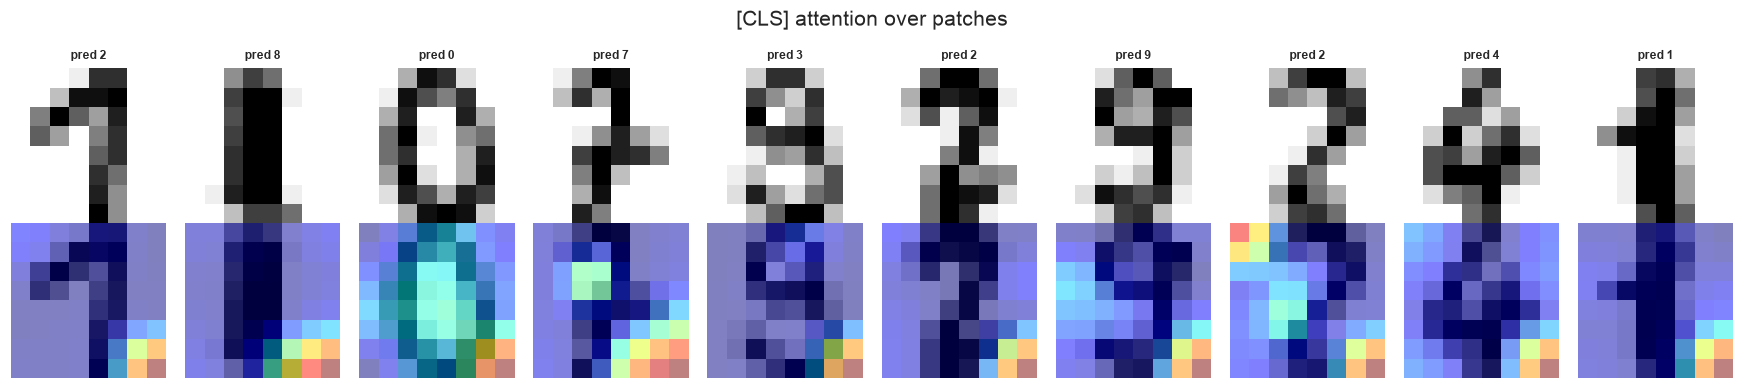

In [4]:
for b in vit.blocks: b.mixer.keep_attn = True
vit.eval(); idx = torch.arange(10); 
with torch.no_grad(): pred = vit(Xva[:10]).argmax(-1)
fig, axs = plt.subplots(2, 10, figsize=(16, 3.6))
for j in range(10):
    a = vit.blocks[-1].mixer.last_attn[j].mean(0)[0, 1:].reshape(4, 4).cpu()
    axs[0, j].imshow(Xva[j].cpu(), cmap="gray_r"); axs[0, j].set_title(f"pred {pred[j].item()}", fontsize=8); axs[0, j].axis("off")
    axs[1, j].imshow(Xva[j].cpu(), cmap="gray_r"); axs[1, j].imshow(F.interpolate(a[None, None], size=8, mode="bilinear")[0, 0], cmap="jet", alpha=.5); axs[1, j].axis("off")
plt.suptitle("[CLS] attention over patches"); plt.tight_layout(); plt.show()

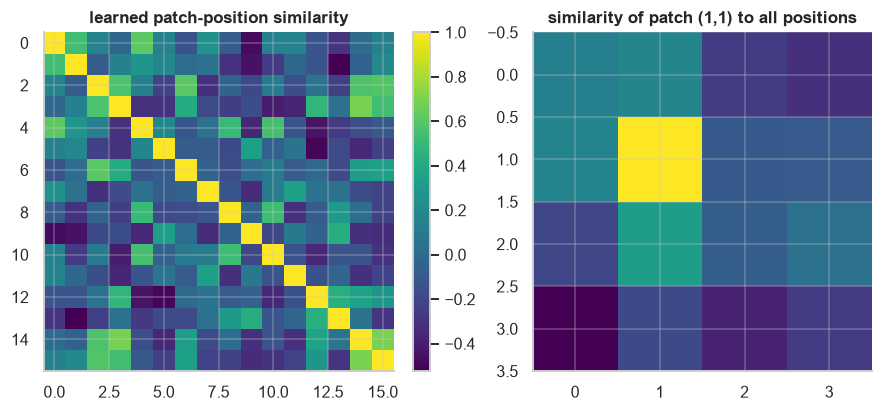

In [5]:
pe = vit.pos.detach()[0, 1:].cpu(); sim = F.normalize(pe, dim=-1) @ F.normalize(pe, dim=-1).T
fig, ax = plt.subplots(1, 2, figsize=(10, 4)); plot_heatmap(sim, title="learned patch-position similarity", ax=ax[0])
ax[1].imshow(sim[5].reshape(4, 4)); ax[1].set_title("similarity of patch (1,1) to all positions"); plt.show()

# ## From ViT to a tiny VLM (LLaVA recipe)
# 1. **Vision encoder** (the ViT above, frozen features) → 16 patch vectors
# 2. **Projector** (MLP) → LM embedding space
# 3. **Language model** (causal decoder). Input sequence: `[img₁ … img₁₆] <bos> s e v e n <eos>`; loss on the text part only.
#
# The "caption" is the digit's name written in letters, so the LM must read the picture to answer.

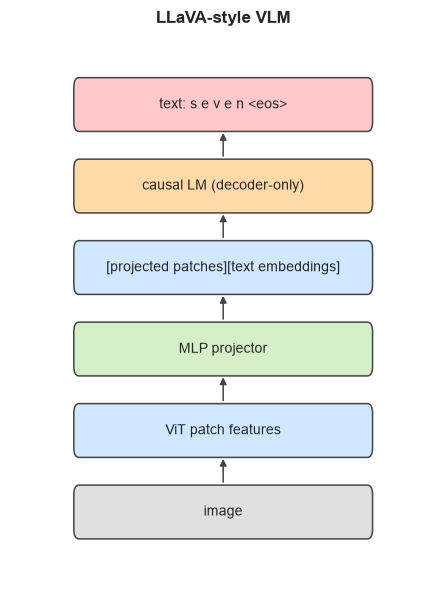

trainable params (projector + LM): 353,664


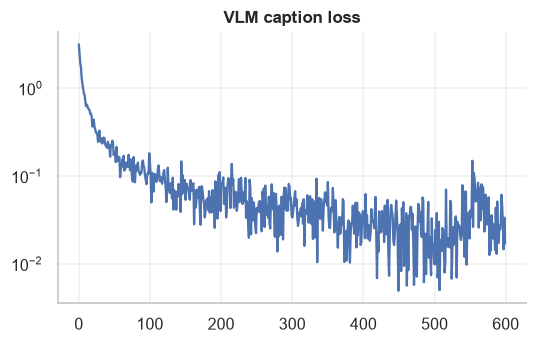

In [6]:
block_diagram([("text: s e v e n <eos>", "out"), ("causal LM (decoder-only)", "attn*"), ("[projected patches][text embeddings]", "embed"), ("MLP projector", "ffn"), ("ViT patch features", "embed"), ("image", "other")][::-1], title="LLaVA-style VLM")
words = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
vocab = ["<pad>", "<bos>", "<eos>"] + sorted(set("".join(words))); stoi = {c: i for i, c in enumerate(vocab)}; VT = len(vocab); LT = 7
def encode(w): return [1] + [stoi[c] for c in w] + [2] + [0] * (LT - len(w) - 2) if len(w) + 2 <= LT else None
def cap(y): return torch.tensor([encode(words[int(i)]) for i in y], device=device)
for p in vit.parameters(): p.requires_grad = False
class VLM(nn.Module):
    def __init__(s, vision, d=96, n=3):
        super().__init__(); s.vision = vision; s.proj = nn.Sequential(nn.Linear(64, d), nn.GELU(), nn.Linear(d, d)); s.tok = nn.Embedding(VT, d); s.pos = nn.Embedding(16 + LT, d)
        s.blocks = nn.ModuleList([Block(d, Attention(d, 4, bias=False), SwiGLU(d)) for _ in range(n)]); s.norm = RMSNorm(d); s.head = nn.Linear(d, VT, bias=False)
    def forward(s, img, text):
        with torch.no_grad(): f = s.vision.features(img)[:, 1:]
        x = torch.cat([s.proj(f), s.tok(text)], 1); x = x + s.pos(torch.arange(x.size(1), device=x.device))
        for b in s.blocks: x, _ = b(x)
        return s.head(s.norm(x))[:, 16:]                                   # logits at text positions
vlm = VLM(vit).to(device); print(f"trainable params (projector + LM): {sum(p.numel() for p in vlm.parameters() if p.requires_grad):,}")
opt = torch.optim.AdamW([p for p in vlm.parameters() if p.requires_grad], lr=3e-3); ls = []
for step in range(600):
    ix = torch.randint(len(Xtr), (64,), device=device); t = cap(ytr[ix]); lg = vlm(Xtr[ix], t)
    loss = F.cross_entropy(lg[:, :-1].reshape(-1, VT), t[:, 1:].reshape(-1), ignore_index=0); opt.zero_grad(); loss.backward(); opt.step(); ls.append(loss.item())
plt.figure(figsize=(5.5, 3.2)); plt.semilogy(ls); plt.title("VLM caption loss"); plt.grid(alpha=.3); plt.show()

caption exact-match accuracy: 85.6%


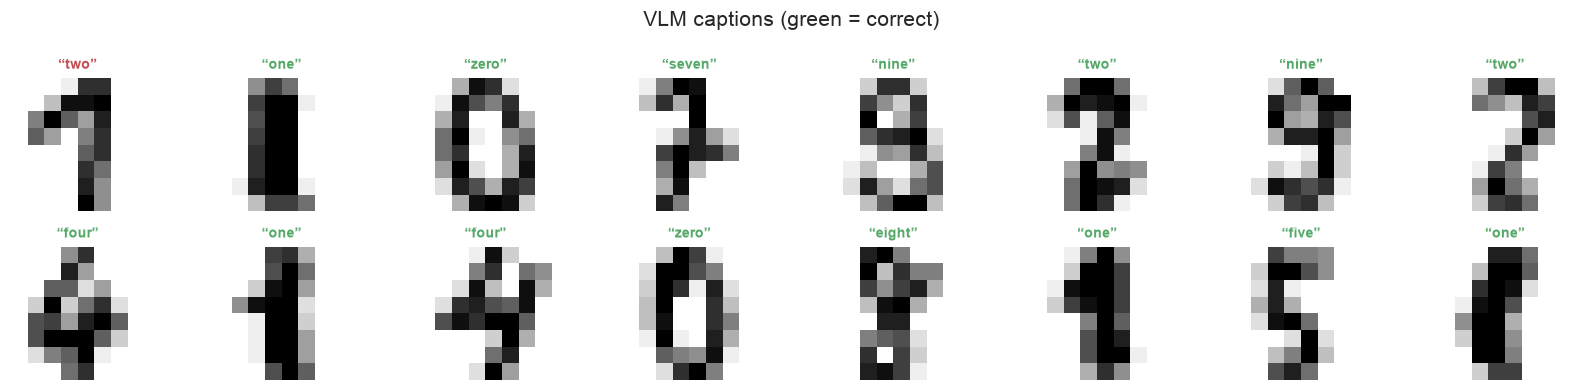

In [7]:
@torch.no_grad()
def caption(img):
    vlm.eval(); t = torch.ones((len(img), 1), dtype=torch.long, device=device)
    for _ in range(LT - 1): t = torch.cat([t, vlm(img, F.pad(t, (0, LT - t.size(1))))[:, t.size(1) - 1].argmax(-1, keepdim=True)], 1)
    out = []
    for r in t.tolist():
        s = ""; 
        for c in r[1:]:
            if c == 2: break
            s += vocab[c]
        out.append(s)
    return out
caps = caption(Xva); acc = np.mean([c == words[int(y)] for c, y in zip(caps, yva)]); print(f"caption exact-match accuracy: {acc:.1%}")
fig, axs = plt.subplots(2, 8, figsize=(15, 3.6))
for a, x, c, y in zip(axs.flat, Xva, caps, yva): a.imshow(x.cpu(), cmap="gray_r"); a.set_title(f"“{c}”", color="g" if c == words[int(y)] else "r", fontsize=9); a.axis("off")
plt.suptitle("VLM captions (green = correct)"); plt.tight_layout(); plt.show()

---

## Key takeaways

- A ViT is a plain Transformer encoder applied to linearly embedded patches.
- A VLM only needs a *projector* to make visual features look like word embeddings.
- Freezing the vision encoder and training the projector + LM is a cheap and effective recipe.

## References

- [Dosovitskiy et al., *An Image is Worth 16x16 Words* (ViT, 2020)](https://arxiv.org/abs/2010.11929)
- [Liu et al., *Visual Instruction Tuning* (LLaVA, 2023)](https://arxiv.org/abs/2304.08485)
- [Radford et al., *CLIP* (2021)](https://arxiv.org/abs/2103.00020)

---
*← previous: `11_hybrid_jamba`  ·  next: `13_diffusion_language_model` →*